# Base Declaration of Project Libraries
> To ensure effective data cleaning & ingestion; reduce the size of the entire dataset and execute standard formatting processes on each file.

In [1]:
import boto3
import psycopg2

import pandas as pd
import numpy as np
from dotenv import load_dotenv
import re
import glob
import chardet
import logging

import os
import csv
import logging
import openpyxl
from xlsx2csv import Xlsx2csv
from datetime import datetime
from typing import Tuple, Optional

import simplejson as json
import random
from datetime import datetime
from dateutil import parser
import matplotlib.pyplot as plt
import math
import mysql.connector

In [3]:
BASE_PATH = f"./datasets/samples/"
RECORDS_PATH = f"{BASE_PATH}/records/"
TO_BE_INGESTED_PATH = f"{BASE_PATH}/to-be-ingested/"
GARBAGE_PATH = f"{BASE_PATH}/garbage/"

In [ ]:
# Specify the path to the folder containing the files
file_path = RECORDS_PATH  
output_folder = f"{RECORDS_PATH}chunks/"

def split_file(file_path, chunk_size, output_directory):
    os.makedirs(output_directory, exist_ok=True)
    
    with open(file_path, 'rb') as file:
        file_count = 0
        current_size = 0
        output_file = None
        
        for line in file:
            if output_file is None or current_size >= chunk_size * 1024 * 1024:
                if output_file:
                    output_file.close()
                file_count += 1
                current_size = 0
                file_name = f'sample_{str(file_count).zfill(3)}.csv'
                current_file_path = os.path.join(output_directory, file_name)
                output_file = open(current_file_path, 'w', encoding='utf-8')

            try:
                decoded_line = line.decode('utf-8')  # Try decoding with UTF-8
            except UnicodeDecodeError:
                decoded_line = line.decode('latin-1')  # If that fails, try decoding with Latin-1

            #Write the decoded line without adding extra line breaks
            if decoded_line.strip():
                output_file.write(decoded_line.strip() + '\n') #Ensures a single newline between records
                current_size += len(line)

        if output_file:
            output_file.close()

    print(f'Splitting complete. Total files created: {file_count}')

# Usage
split_file(file_path, 250, output_folder)


In [ ]:

# --- Desired Output Columns ---
COLUMNS = ["firstname", "lastname", "email", "username", "password", "salt", "phone"]
COLUMN_INDICES = [3, 4, 5, 6, 7, 8, 18]

INSERT_START_RE = re.compile(
    r"INSERT\s+INTO\s+`reg_users_list`\s*\(.*?\)\s*VALUES",
    re.IGNORECASE
)

TUPLE_RE = re.compile(r"\((.*?)\)(?:,|$)", re.DOTALL)


def clean_sql_value(value: str):
    value = value.strip()

    if value.upper() == "NULL":
        return None

    if value.startswith("'") and value.endswith("'"):
        return value[1:-1].replace("\\'", "'").replace('\\\\', '\\')

    return value


def extract_values(record: str):
    values = []
    current = ''
    in_quotes = False
    escape = False

    for char in record:
        if escape:
            current += char
            escape = False
        elif char == "\\":
            current += char
            escape = True
        elif char == "'":
            in_quotes = not in_quotes
            current += char
        elif char == "," and not in_quotes:
            values.append(clean_sql_value(current))
            current = ''
        else:
            current += char

    if current:
        values.append(clean_sql_value(current))

    return values


def stream_insert_tuples_v1(file_handle):
    collecting = False
    buffer = []

    for line in file_handle:
        if INSERT_START_RE.search(line):
            collecting = True
            buffer = []
            continue

        if collecting:
            buffer.append(line)

            if ");" in line:
                full_block = "".join(buffer)
                yield full_block
                collecting = False
                buffer = []

def stream_insert_tuples(file_handle):
    collecting = False
    buffer = []

    for line in file_handle:
        if INSERT_START_RE.search(line):
            collecting = True
            buffer = []
            continue

        if collecting:
            # Stop if a new INSERT begins (different table)
            if line.strip().upper().startswith("INSERT INTO"):
                yield "".join(buffer)
                collecting = False
                buffer = []

            buffer.append(line)

            if line.strip().endswith(";"):
                yield "".join(buffer)
                collecting = False
                buffer = []


def process_file(input_file: str, output_file: str, garbage_file: str):
    os.makedirs(os.path.dirname(output_file), exist_ok=True)
    os.makedirs(os.path.dirname(garbage_file), exist_ok=True)

    valid_count = 0
    garbage_count = 0

    with open(input_file, 'r', encoding='utf-8', errors='ignore') as infile, \
         open(output_file, 'w', newline='', encoding='utf-8') as csvfile, \
         open(garbage_file, 'w', newline='', encoding='utf-8') as gfile:

        writer = csv.writer(csvfile)
        garbage_writer = csv.writer(gfile)

        writer.writerow(COLUMNS)
        garbage_writer.writerow(["raw_tuple"])

        for insert_block in stream_insert_tuples(infile):

            tuples = TUPLE_RE.findall(insert_block)

            for tup in tuples:
                try:
                    values = extract_values(tup)

                    if len(values) <= max(COLUMN_INDICES):
                        garbage_writer.writerow([tup])
                        garbage_count += 1
                        continue

                    row = [
                        values[i] if i < len(values) else None
                        for i in COLUMN_INDICES
                    ]

                    writer.writerow(row)
                    valid_count += 1

                except Exception as e:
                    logging.error(f"Failed to parse tuple: {tup[:80]}... Error: {e}")
                    garbage_writer.writerow([tup])
                    garbage_count += 1

    logging.info(f"{input_file}: Extracted {valid_count} valid rows, {garbage_count} garbage rows")


def process_folder(input_folder: str, output_folder: str, garbage_folder: str):
    os.makedirs(output_folder, exist_ok=True)
    os.makedirs(garbage_folder, exist_ok=True)

    for filename in os.listdir(input_folder):
        if not filename.endswith(".txt"):
            continue

        input_path = os.path.join(input_folder, filename)
        output_path = os.path.join(output_folder, f"{os.path.splitext(filename)[0]}.csv")
        garbage_path = os.path.join(garbage_folder, f"garbage_{os.path.splitext(filename)[0]}.csv")

        logging.info(f"Processing: {input_path}")

        process_file(input_path, output_path, garbage_path)

        logging.info(f"Finished: {filename}")


if __name__ == "__main__":
    input_folder = f"{RECORDS_PATH}chunks/"  # Path to folder with text files
    output_folder = f"{TO_BE_INGESTED}"
    garbage_folder = f"{GARBAGE_PATH}"

    process_folder(input_folder, output_folder, garbage_folder)


In [ ]:
COLUMNS = [
    "username", "email", "password", "salt", "dob", "url", "ip"
]
COLUMN_INDICES = [1, 5, 2, 3, 25, 19, 66]

# Regex patterns for parsing nested records
RECORD_PATTERN = re.compile(r"\((.*?)\),|;\)")

def extract_values(record):
    values = []
    current = ''
    inside_quotes = False

    for char in record:
        if char == "'":
            inside_quotes = not inside_quotes
            current += char
        elif char == ',' and not inside_quotes:
            values.append(current.strip())
            current = ''
        else:
            current += char

    if current:
        values.append(current.strip())
    return values

def process_file(input_file, output_file):
    with open(input_file, 'r', encoding='utf-8') as infile, \
         open(output_file, 'w', newline='', encoding='utf-8') as outfile:
        
        writer = csv.writer(outfile)
        writer.writerow(COLUMNS)  
        
        for line_number, line in enumerate(infile, start=1):
            try:
                matches = RECORD_PATTERN.findall(line)
                for match in matches:
                    raw_values = extract_values(match)
                    if len(raw_values) > max(COLUMN_INDICES):
                        # Extract only the required columns
                        row = [raw_values[i] if i < len(raw_values) else None for i in COLUMN_INDICES]
                        writer.writerow(row)
            except Exception as e:
                logging.error(f"Error processing line {line_number} in {input_file}: {e}")

def process_folder(input_folder, output_folder):
    os.makedirs(output_folder, exist_ok=True)
    
    for filename in os.listdir(input_folder):
        if filename.endswith(".sql"):
            input_file = os.path.join(input_folder, filename)
            output_file = os.path.join(output_folder, f"{os.path.splitext(filename)[0]}.csv")
            logging.info(f"Processing file: {input_file}")
            process_file(input_file, output_file)
            logging.info(f"File processed: {output_file}")

if __name__ == "__main__":
    input_folder = f"{RECORDS_PATH}chunks/" 
    output_folder = f"{TO_BE_INGESTED}" 
    process_folder(input_folder, output_folder)


In [ ]:

# Specify columns to extract and their indices
COLUMNS = [
    "username", "email", "crypted_password", "salt",
    "dob", "url", "ip"
]
COLUMN_INDICES = [4, 7, 5, 48, 36, 10, 40]

# Updated regex pattern for matching SQL records
RECORD_PATTERN = re.compile(r"(?:,?\()(.*?)(?=\),|;\)|\))")

def extract_values(record):
    """Extract values from a single record."""
    values = []
    current = ''
    inside_quotes = False

    for char in record:
        if char == "'":
            inside_quotes = not inside_quotes
            current += char
        elif char == ',' and not inside_quotes:
            values.append(current.strip())
            current = ''
        else:
            current += char

    if current:
        values.append(current.strip())
    return values

def process_file(input_file, output_file):
  
    with open(input_file, 'r', encoding='utf-8') as infile, \
         open(output_file, 'w', newline='', encoding='utf-8') as outfile:
        
        writer = csv.writer(outfile)
        writer.writerow(COLUMNS)  # Write CSV header
        
        for line_number, line in enumerate(infile, start=1):
            try:
                # Find all matching records in the line
                matches = RECORD_PATTERN.findall(line)
                for match in matches:
                    raw_values = extract_values(match)
                    if len(raw_values) > max(COLUMN_INDICES):
                        # Extract only the required columns
                        row = [raw_values[i] if i < len(raw_values) else None for i in COLUMN_INDICES]
                        writer.writerow(row)
            except Exception as e:
                logging.error(f"Error processing line {line_number} in {input_file}: {e}")

def process_folder(input_folder, output_folder):

    os.makedirs(output_folder, exist_ok=True)
    
    for filename in os.listdir(input_folder):
        if filename.endswith(".csv"):
            input_file = os.path.join(input_folder, filename)
            output_file = os.path.join(output_folder, f"{os.path.splitext(filename)[0]}.csv")
            logging.info(f"Processing file: {input_file}")
            process_file(input_file, output_file)
            logging.info(f"File processed: {output_file}")

if __name__ == "__main__":
    input_folder = f"{RECORDS_PATH}chunks/"
    output_folder = f"{TO_BE_INGESTED}"
    process_folder(input_folder, output_folder)


In [ ]:

HEADER = ["firstname", "lastname", "email", "phone", "dob", "street", "city", "state", "zipcode", "country"]


def clean(value):
    if value is None:
        return ""
    return str(value).strip()


def extract_record(record):

    return [
        clean(record.get("FirstName")),
        clean(record.get("LastName")),
        clean(record.get("PersonEmail")),
        clean(record.get("PersonMobilePhone")),
        clean(record.get("PersonBirthdate")),
        clean(record.get("BillingStreet")),
        clean(record.get("BillingCity")),
        clean(record.get("BillingState")),
        clean(record.get("BillingPostalCode")),
        clean(record.get("BillingCountry"))
    ]


def read_json_adaptive(input_file):
    """
    Handles:
    1. Normal JSON object
    2. JSON array
    3. NDJSON / JSON Lines
    """

    with open(input_file, "r", encoding="utf-8-sig") as infile:
        content = infile.read().strip()

    # Attempt 1: normal JSON object or JSON array
    try:
        data = json.loads(content)

        if isinstance(data, dict):
            return [data]

        if isinstance(data, list):
            return data

    except json.JSONDecodeError:
        pass

    # Attempt 2: NDJSON / JSON Lines
    records = []

    with open(input_file, "r", encoding="utf-8-sig") as infile:
        for line_number, line in enumerate(infile, start=1):
            line = line.strip()

            if not line:
                continue

            try:
                record = json.loads(line)
                records.append(record)
            except json.JSONDecodeError as e:
                print(f"Bad JSON line {line_number}: {e}")

    return records


def process_json_file(input_file, output_file, garbage_file):
    records = read_json_adaptive(input_file)

    valid_count = 0
    garbage_count = 0

    with open(output_file, "w", newline="", encoding="utf-8") as outfile, \
         open(garbage_file, "w", encoding="utf-8") as gfile:

        writer = csv.writer(outfile)
        writer.writerow(HEADER)

        for record in records:
            try:
                extracted = extract_record(record)

                email = extracted[2]

                if not email:
                    garbage_count += 1
                    gfile.write(json.dumps(record, ensure_ascii=False) + "\n")
                    continue

                writer.writerow(extracted)
                valid_count += 1

            except Exception as e:
                garbage_count += 1
                gfile.write(json.dumps(record, ensure_ascii=False) + "\n")

    print("Extraction complete.")
    print(f"Valid records: {valid_count}")
    print(f"Garbage records: {garbage_count}")


def main():
    
    os.makedirs(TO_BE_INGESTED_PATH, exist_ok=True)
    os.makedirs(GARBAGE_PATH, exist_ok=True)
    
    json_files = [file for file in os.listdir(RECORDS_PATH) if file.endswith(".json")]
    for json_file in json_files:
        input_file_path = os.path.join(RECORDS_PATH, json_file)
        output_file_path = os.path.join(TO_BE_INGESTED_PATH, f"processed_{json_file}")
        garbage_file_path = os.path.join(GARBAGE_PATH, f"garbage_{json_file}")
        
        process_json_file(input_file_path, output_file_path, garbage_file_path)


if __name__ == "__main__":
    main()


Detected encoding: UTF-8-SIG


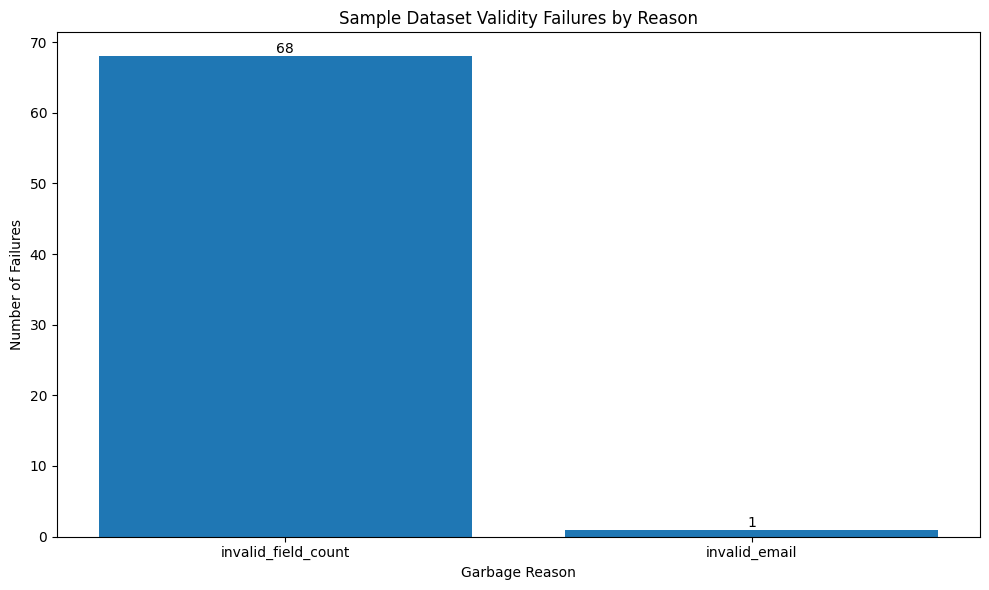

In [7]:

import sys
import csv
csv.field_size_limit(min(sys.maxsize, 2147483647))
import logging
from datetime import datetime
import re
import os

# Regex Patterns
NAME_PATTERN = re.compile(r"^[A-Za-zÀ-ÖØ-öø-ÿ' -]+$")
EMAIL_PATTERN = r"^[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}$"
IPV4_PATTERN = r'^(\d{1,3}\.){3}\d{1,3}$'
EMAIL_PATTERN = r'^[^@\s]+@[^@\s]+\.[^@\s]+$'
PHONE_PATTERN = r'^[0-9().+ ]+$'



HEADER = ["firstname", "lastname", "email", "phone", "address", "city", "zipcode", "ip_address"]
MAX_NAME_LENGTH = 32

# Utility functions
def truncate_field(field: str, limit=64) -> str:
    return field.strip()[:limit] if field else None

def to_camel_case(s: str) -> str:
    return ' '.join(word.capitalize() for word in s.split()) if s else None

def validate_pattern(pattern: str, value: str) -> bool:
    return bool(re.fullmatch(pattern, value.strip())) if value else False

def convert_date_format(date_str: str) -> str:
    if not date_str or date_str.strip().lower() == "none":
        return None

    date_str = date_str.strip()
    
    for fmt in ("%Y-%m-%d %H:%M:%S", "%m/%d/%Y", "%d-%m-%Y", "%d.%m.%Y", "%Y-%m-%d"):  # Checking both formats
        try:
            return datetime.strptime(date_str, fmt).strftime("%m/%d/%Y")
        except ValueError:
            continue

    return None  # If the format is unrecognized

def split_name(name: str) -> Tuple[Optional[str], Optional[str]]:
    """Splits full name into first and last name."""
    if not name.strip():
        return None, None
    name_parts = name.split()
    return name_parts[0], " ".join(name_parts[1:]) if len(name_parts) > 1 else None

def process_email(email: Optional[str]) -> Optional[str]:
    if email:
        email = email.strip().lower()
        if validate_pattern(r'^[^@\s]+@[^@\s]+\.[^@\s]+$', email):
            return email
    return None

def process_phone(phone: Optional[str]) -> Optional[str]:
    phone_pattern = r'^[0-9().+ ]+$'
    if phone and re.fullmatch(phone_pattern, phone.strip()):
        return phone.strip()
    return None

def is_valid_name(name: Optional[str]) -> bool:
    if not name:
        return True
    name = name.strip()
    return (
        len(name) <= MAX_NAME_LENGTH 
        and validate_pattern(NAME_PATTERN, name)
    )

def to_lower(s: Optional[str]) -> Optional[str]:
    return s.lower() if s else None

def to_upper(s: Optional[str]) -> Optional[str]:
    return s.upper() if s else None

def to_camel_case(s: Optional[str]) -> Optional[str]:
    return None if s is None else ' '.join(word.capitalize() for word in s.split())

def is_valid_ipv4(ip):
    if not re.fullmatch(IPV4_PATTERN, ip):
        return False
    parts = ip.split('.')
    return all(0 <= int(part) <= 255 for part in parts)

def process_ipaddress(ip):
    if not ip:
        return None
    ip = ip.strip()
    return ip if is_valid_ipv4(ip) else None


def is_digit(value: str) -> bool:
    if not value:
        return False
    value = value.strip()
    return value.isdigit()


def is_text(value: str) -> bool:
    if not value:
        return False
    value = value.strip()
    return value.replace(" ", "").isalpha()

from pypinyin import pinyin, Style
from typing import Optional

def fix_mojibake(text):
    try:
        return text.encode("mac_roman").decode("utf-8")
    except:
        return text


def truncate_to_max_bytes(value: str, max_bytes: int, encoding='utf-8') -> str:
    """Truncates a string to a maximum byte length while maintaining valid characters."""
    if not value:
        return ""
    encoded = value.encode(encoding)
    if len(encoded) <= max_bytes:
        return value
    truncated = encoded[:max_bytes]
    while True:
        try:
            return truncated.decode(encoding)
        except UnicodeDecodeError:
            truncated = truncated[:-1]

def safe_len(value):
    return len(value) if value else 0

def is_text(value: str) -> bool:
    if not value:
        return False
    value = value.strip()
    return value.replace(" ", "").isalpha()  # Checks if all non-space characters are alphabetic


def convert_name(chinese_name: str) -> tuple[str, str, str]:
  
    username = chinese_name.strip()
    if not username:
        return None, None, None

    # Family name is the first character, given name is the rest
    family_char = username[0]
    given_chars = username[1:]

    def to_pinyin(chars: str) -> str:
        syllables = pinyin(chars, style=Style.NORMAL)
        return ''.join(s[0].capitalize() for s in syllables)

    firstname = to_pinyin(family_char)
    lastname = to_pinyin(given_chars)

    return username, firstname, lastname


def process_row(row: list) -> list:
    
    errors = []
    if len(row) < 29:
        return None, ["invalid_field_count"]

    try:
        # Extract and clean fields
        
        # firstname, lastname = split_name(row[0].replace('"', '').replace("'", "").replace(",", "").strip())
        firstname = fix_mojibake(to_camel_case(row[7].replace('"', '').replace("'", "").replace(",", "").replace("NULL", "").replace("Null", "").replace("None", "").replace("Unknown", "").strip()))
        lastname = fix_mojibake(to_camel_case(row[8].replace('"', '').replace("'", "").replace(",", "").replace("NULL", "").replace("Null", "").replace("None", "").replace("Unknown", "").strip()))
        email = fix_mojibake(row[9].replace('"', '').replace("'", "").replace(",", "").strip())
        phone = process_phone(row[10].replace('"', '').replace("'", "").replace(",", "").replace("NULL", "").replace("Null", "").replace("None", "").replace("Unknown", "").strip())
        address = truncate_field(fix_mojibake(row[13].replace('"', '').replace("'", "").replace(",", "").replace("*", "").replace(":", "").replace("?", "").replace("/", "").strip()), 128)
        zipcode = truncate_field(to_upper(fix_mojibake(row[11].replace('"', '').replace("'", "").replace(",", "").replace("NULL", "").replace("Null", "").replace("None", "").replace(" ", "").strip())), 128)
        city = truncate_field(to_camel_case(fix_mojibake(row[12].replace('"', '').replace("'", "").replace(",", "").replace("NULL", ""). replace("Null", ""). replace("None", ""). replace("Unknown", "").strip())), 128)
        ip_address = process_ipaddress(row[28].replace('"', '').replace("'", "").replace(",", "").replace("NULL", ""). replace("Null", ""). replace("None", ""). replace("Unknown", "").strip())

        # if firstname is not None and not is_valid_name(firstname):
        #     errors.append("invalid_firstname")

        # if lastname is not None and not is_valid_name(lastname):
        #     errors.append("invalid_lastname")

        if email is not None and not process_email(email):
            errors.append("invalid_email")

        # if email is None:
        #     errors.append("missing_email")
     
        if errors:
            return None, errors
      
        return [firstname, lastname, email, phone, address, city, zipcode, ip_address], []
    except Exception as e:
        # logging.error(f"Error processing row {row}: {e}")
        return None, [f"processing_exception:{type(e).__name__}"]
        

def detect_encoding(file_path, sample_size=10000):
    with open(file_path, 'rb') as f:
        raw_data = f.read(sample_size)
    result = chardet.detect(raw_data)
    return result['encoding']

def process_file(input_file: str, output_file: str, garbage_file: str, garbage_reason_file: str) -> None:
    os.makedirs(os.path.dirname(output_file), exist_ok=True)
    os.makedirs(os.path.dirname(garbage_file), exist_ok=True)
    os.makedirs(os.path.dirname(garbage_reason_file), exist_ok=True)

    detected_encoding = detect_encoding(input_file)
    print(f"Detected encoding: {detected_encoding}")

    with open(input_file, 'r', encoding="utf-8-sig", errors='strict') as infile:
    # with open(input_file, 'r', encoding="mac_roman", errors="replace", newline="") as infile:
        sample = infile.read(1024)
        infile.seek(0)

        try:
            dialect = csv.Sniffer().sniff(sample, delimiters=";")
        except csv.Error:
            dialect = csv.excel
            dialect.delimiter = ';'

        reader = csv.reader(infile, dialect)

        with open(output_file, 'w', newline='', encoding='utf-8') as outfile, \
             open(garbage_file, 'w', newline='', encoding='utf-8') as gfile, \
             open(garbage_reason_file, 'w', newline='', encoding='utf-8') as greasonfile:

            writer = csv.writer(outfile)
            garbage_writer = csv.writer(gfile)
            garbage_reason_writer = csv.writer(greasonfile)

            writer.writerow(HEADER)
            garbage_writer.writerow(["garbage_reasons"])
            garbage_reason_writer.writerow(["garbage_reasons"])

            # next(reader, None)``

            for row in reader:
                processed_row, errors = process_row(row)
                if processed_row:
                    writer.writerow(processed_row)
                else:
                    reasons = errors if errors else ["unknown_error"]
                    garbage_writer.writerow(row + ["|".join(reasons)])
                    for error in errors:
                        garbage_reason_writer.writerow([error])


import pandas as pd
import matplotlib.pyplot as plt

def chart_garbage_reasons(reason_file):
    df = pd.read_csv(reason_file)

    counts = df["garbage_reasons"].value_counts()

    plt.figure(figsize=(10, 6))
    bars = plt.bar(counts.index, counts.values)

    plt.xlabel("Garbage Reason")
    plt.ylabel("Number of Failures")
    plt.title("Sample Dataset Validity Failures by Reason")
    plt.xticks(rotation=0, ha="center")

    for bar in bars:
        yval = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            yval,
            f"{int(yval):,}",
            ha="center",
            va="bottom"
        )

    plt.tight_layout()
    plt.show()


def main():
    
    os.makedirs(f"{TO_BE_INGESTED_PATH}", exist_ok=True)
    os.makedirs(f"{GARBAGE_PATH}", exist_ok=True)

    csv_files = [file for file in os.listdir(f"{RECORDS_PATH}") if file.endswith(".csv")]
    for csv_file in csv_files:
        input_file_path = os.path.join(f"{RECORDS_PATH}", csv_file)
        output_file_path = os.path.join(f"{TO_BE_INGESTED_PATH}", f"processed_{csv_file}")
        garbage_file_path = os.path.join(f"{GARBAGE_PATH}", f"garbage_{csv_file}")
        garbage_reason_file_path = os.path.join(f"{GARBAGE_PATH}", f"garbage_reasons_{csv_file}")
        
        process_file(input_file_path, output_file_path, garbage_file_path, garbage_reason_file_path)
        chart_garbage_reasons(garbage_reason_file_path)
        
if __name__ == "__main__":
    main()


In [8]:

def remove_empty_lines(input_file, output_file, garbage_file=None):
    try:
        with open(input_file, 'r', encoding='utf-8') as infile, open(output_file, 'w', encoding='utf-8') as outfile, open(garbage_file, 'w', encoding='utf-8') if garbage_file else open(os.devnull, 'w') as gfile:
            for line in infile:
                # Strip leading/trailing whitespace and check if line is not empty
                if line.strip() and ',,,,,' not in line and ',,NULL,NULL,,' not in line:
                    outfile.write(line)
                elif garbage_file:
                    gfile.write(line)
        a
        print(f"Lines with specified text removed successfully from {input_file}!")
    except Exception as e:
        print(f"An error occurred with file {input_file}: {e}")

input_folder = TO_BE_INGESTED_PATH
output_folder = f"{TO_BE_INGESTED_PATH}final/"
garbage_folder = f"{BASE_PATH}/garbage/final/"

os.makedirs(output_folder, exist_ok=True)
os.makedirs(garbage_folder, exist_ok=True)

# List all CSV files in the input folder
csv_files = [file for file in os.listdir(input_folder) if file.endswith(".csv")]

for csv_file in csv_files:
    input_file_path = os.path.join(input_folder, csv_file)
    output_file_path = os.path.join(output_folder, csv_file) 
    garbage_file_path = os.path.join(garbage_folder, csv_file) 
    remove_empty_lines(input_file_path, output_file_path, garbage_file_path)


An error occurred with file ./datasets/samples//to-be-ingested/processed_messy_sample_4.csv: name 'a' is not defined


In [ ]:

EMAIL_PATTERN = re.compile(r'^[^@\s,]+@[^@\s,]+\.[^@\s,]+$')  # Email validation regex

def is_email_only_line(row):
    """Check if the row contains only an email address and a single trailing value."""
    non_empty_values = [value.strip() for value in row if value.strip()]
    return len(non_empty_values) == 2 and EMAIL_PATTERN.match(non_empty_values[0])

def filter_email_only_lines(input_file, output_file, garbage_file):
    """Removes lines that contain only an email address and one trailing value."""
    os.makedirs(os.path.dirname(output_file), exist_ok=True)
    os.makedirs(os.path.dirname(garbage_file), exist_ok=True)
    
    with open(input_file, 'r', encoding='utf-8') as infile, \
         open(output_file, 'w', newline='', encoding='utf-8') as outfile, \
         open(garbage_file, 'w', newline='', encoding='utf-8') as gfile:
        
        reader = csv.reader(infile)
        writer = csv.writer(outfile)
        garbage_writer = csv.writer(gfile)
        
        header = next(reader, None)  # Read the header
        if header:
            writer.writerow(header)  # Write the header to the output file
        
        for row in reader:
            if is_email_only_line(row):
                garbage_writer.writerow(row)  # Move to garbage
            else:
                writer.writerow(row)  # Keep valid rows
    
    print(f"Processed: {input_file} → {output_file} | Garbage: {garbage_file}")

# Folder Paths
input_folder = f"{RECORDS_PATH}chunks/"
output_folder = f"{RECORDS_PATH}chunks/final/"
garbage_folder = f"{RECORDS_PATH}chunks/garbage/"

# Process CSV files
csv_files = [file for file in os.listdir(input_folder) if file.endswith(".csv")]

for csv_file in csv_files:
    input_file_path = os.path.join(input_folder, csv_file)
    output_file_path = os.path.join(output_folder, csv_file)
    garbage_file_path = os.path.join(garbage_folder, f"garbage_{csv_file}")
    
    filter_email_only_lines(input_file_path, output_file_path, garbage_file_path)


In [9]:

# Specify the path to the folder containing the files

folder_path = f"{TO_BE_INGESTED_PATH}final/"

# Iterate over each file in the folder
for filename in os.listdir(folder_path):
    if filename.endswith(".csv"):
        # Construct the full path to the file
        file_path = os.path.join(folder_path, filename)

        # Read lines, remove specific characters, and update the original file
        with open(file_path, 'r+', encoding='latin-1') as file:
            lines = file.readlines()

            # Remove specific characters from each line
            cleaned_lines = [line.replace('"', '').replace("'", "").replace('\\', '').replace("(", "").replace(")", "").replace("~", "-")           # Add more characters to remove
                             for line in lines]

            # Move the file pointer to the beginning and truncate the file
            file.seek(0)
            file.truncate()

            # Write the cleaned lines back to the file
            file.writelines(cleaned_lines)

        print(f"Specific characters removed from the file: {filename}")

print("Cleaning operation completed for all files in the folder.")


Specific characters removed from the file: processed_messy_sample_4.csv
Cleaning operation completed for all files in the folder.


In [ ]:
import os
import glob
import pandas as pd


input_folder = "{RECRORDS_PATH}chunks/final/"
output_folder = "{RECORDS_PATH}chunks/final/wd/"

# Create output folder if it doesn't exist
os.makedirs(output_folder, exist_ok=True)

csv_files = glob.glob(os.path.join(input_folder, "*.csv"))

for file_path in csv_files:
    # Generate output file name based on input file name
    file_name = os.path.basename(file_path)
    output_file_name = os.path.join(output_folder, file_name.replace(".csv", "_wd.csv"))
    
    # Read CSV, drop duplicates, and save the updated file
    disqus_dataset = pd.read_csv(file_path, low_memory=True)
    disqus_wd_dataset = disqus_dataset.drop_duplicates(subset=["email"])
    disqus_wd_dataset.to_csv(output_file_name, encoding='utf-8', index=False)
    
    # Reload the new file to check the info
    disqus_dataset = pd.read_csv(output_file_name, low_memory=True)
    disqus_dataset.info()
    print(f"Processed file: {output_file_name}")


In [ ]:

# Function to clean non-UTF-8 characters from a string
def clean_string(s):
    # Remove characters that aren't valid UTF-8
    return re.sub(r'[^\x00-\x7F]+', '', s)

# Specify the path to the folder containing the files
folder_path = f"{RECORDS_PATH}chunks/final/"

# Iterate over each file in the folder
for filename in os.listdir(folder_path):
    if filename.endswith(".csv"):
        # Construct the full path to the file
        file_path = os.path.join(folder_path, filename)
        
        # Construct the output file path based on the input file name
        output_file = os.path.join(folder_path, f"cleaned_{filename}")
        
        # Read lines, clean specific characters, and update the original file
        with open(file_path, 'r', encoding='utf-8', errors='replace') as infile:
            with open(output_file, 'w', encoding='utf-8', newline='') as outfile:
                reader = csv.reader(infile)
                writer = csv.writer(outfile)
                for row in reader:
                    # Clean non-UTF-8 characters from each cell in the row
                    cleaned_row = [clean_string(cell) for cell in row]
                    writer.writerow(cleaned_row)

print("Cleaning operation completed for all files in the folder.")


In [10]:

# Regex Patterns
NAME_PATTERN = re.compile(r'^[A-Za-zÀ-ÖØ-öø-ÿ\s\'-]+$') 
EMAIL_PATTERN = r'^[^@\s]+@[^@\s]+\.[^@\s]+$'
PHONE_PATTERN = r'^[0-9().+ ]+$'

# Constants
HEADER = ["firstname", "lastname", "email", "phone", "address", "city", "zipcode", "ip_address"]
MAX_NAME_LENGTH = 32

# Utility functions
def truncate_field(field: str, limit=64) -> str:
    return field.strip()[:limit] if field else None

def to_camel_case(s: str) -> str:
    return ' '.join(word.capitalize() for word in s.split()) if s else None

def validate_pattern(pattern: str, value: str) -> bool:
    return bool(re.fullmatch(pattern, value.strip())) if value else False

def convert_date_format(date_str: str) -> str:
    if not date_str or date_str.strip().lower() == "none":
        return None

    date_str = date_str.strip()
    
    for fmt in ("%Y-%m-%d %H:%M:%S", "%m/%d/%Y", "%d-%m-%Y", "%Y-%m-%d"):  # Checking both formats
        try:
            return datetime.strptime(date_str, fmt).strftime("%m/%d/%Y")
        except ValueError:
            continue

    return None  # If the format is unrecognized


def process_email(email: Optional[str]) -> Optional[str]:
    if email:
        email = email.strip().lower()
        if validate_pattern(r'^[^@\s]+@[^@\s]+\.[^@\s]+$', email):
            return email
    return None

def process_phone(phone: Optional[str]) -> Optional[str]:
    phone_pattern = r'^[0-9().+ ]+$'
    if phone and re.fullmatch(phone_pattern, phone.strip()):
        return phone.strip()
    return None

def to_lower(s: Optional[str]) -> Optional[str]:
    return s.lower() if s else None

def to_upper(s: Optional[str]) -> Optional[str]:
    return s.upper() if s else None

def is_valid_ipv4(ip):
    if not re.fullmatch(IPV4_PATTERN, ip):
        return False
    parts = ip.split('.')
    return all(0 <= int(part) <= 255 for part in parts)

def process_ipaddress(ip):
    if not ip:
        return None
    ip = ip.strip()
    return ip if is_valid_ipv4(ip) else None

def is_digit(value: str) -> bool:
    if not value:
        return False
    value = value.strip()
    return value.isdigit()

def fix_mojibake(text):
    try:
        return text.encode("latin-1").decode("utf-8")
    except:
        return text


def truncate_to_max_bytes(value: str, max_bytes: int, encoding='utf-8') -> str:
    """Truncates a string to a maximum byte length while maintaining valid characters."""
    if not value:
        return ""
    encoded = value.encode(encoding)
    if len(encoded) <= max_bytes:
        return value
    truncated = encoded[:max_bytes]
    while True:
        try:
            return truncated.decode(encoding)
        except UnicodeDecodeError:
            truncated = truncated[:-1]

def safe_len(value):
    return len(value) if value else 0

def is_text(value: str) -> bool:
    if not value:
        return False
    value = value.strip()
    return value.replace(" ", "").isalpha()  # Checks if all non-space characters are alphabetic

def process_row(row: list) -> list:
    try:
        firstname = truncate_to_max_bytes(fix_mojibake(row[0].replace('"', '').replace("'", "").replace(",", "")), MAX_NAME_LENGTH)
        lastname = truncate_to_max_bytes(fix_mojibake(row[1].replace('"', '').replace("'", "").replace(",", "")), MAX_NAME_LENGTH)
        email = process_email(row[2].replace('"', '').replace("'", "").replace(",", ""))
        phone = process_phone(row[3].replace('"', '').replace("'", "").replace(",", "").replace("+", "").replace("-", "").replace(" ", ""))
        address = truncate_field(row[4].replace('"', '').replace("'", "").replace(",", ""))
        city = truncate_field(row[5].replace('"', '').replace("'", "").replace(",", ""))
        zipcode = truncate_field(row[6].replace('"', '').replace("'", "").replace(",", "").replace(" ", ""))
        ip_address = process_ipaddress(row[7].replace('"', '').replace("'", "").replace(",", ""))
        
       
        # Validate name fields
        if safe_len(firstname) > 64:
                return None
        if safe_len(lastname) > 64:
                return None
        # Validate email
        return [firstname, lastname, email, phone, address, city, zipcode, ip_address]
    except Exception as e:
        # logging.error(f"Error processing row {row}: {e}")
        return None

def process_file(input_file: str, output_file: str, garbage_file: str) -> None:
    os.makedirs(os.path.dirname(output_file), exist_ok=True)
    os.makedirs(os.path.dirname(garbage_file), exist_ok=True)
    
    with open(input_file, 'r', encoding='utf-8-sig') as infile, \
         open(output_file, 'w', newline='', encoding='utf-8-sig') as outfile, \
         open(garbage_file, 'w', newline='', encoding='utf-8-sig') as gfile:
         
        reader = csv.reader(infile)
        writer = csv.writer(outfile)
        garbage_writer = csv.writer(gfile)
        
        writer.writerow(HEADER)
        # next(reader, None)  # Skip header
        
        for row in reader:
            processed_row = process_row(row)
            if processed_row:
                writer.writerow(processed_row)
            else:
                garbage_writer.writerow(row)

def main():
    input_folder = f"{TO_BE_INGESTED_PATH}final/"
    output_folder = f"{TO_BE_INGESTED_PATH}final/v2/"
    garbage_folder = f"{TO_BE_INGESTED_PATH}final/garbage/v2/"
    
    os.makedirs(output_folder, exist_ok=True)
    os.makedirs(garbage_folder, exist_ok=True)
    
    csv_files = [file for file in os.listdir(input_folder) if file.endswith(".csv")]
    for csv_file in csv_files:
        input_file_path = os.path.join(input_folder, csv_file)
        output_file_path = os.path.join(output_folder, f"processed_{csv_file}")
        garbage_file_path = os.path.join(garbage_folder, f"garbage_{csv_file}")
        
        process_file(input_file_path, output_file_path, garbage_file_path)

if __name__ == "__main__":
    main()


In [ ]:
import os
import csv

# firstname,lastname,email,phone,address
# Configuration
input_folder = "{RECRORDS_PATH}chunks/final/" 
output_file = "{TO_BE_INGESTED_PATH}final/samples_merged.csv"
expected_header = ["firstname", "lastname", "email", "phone", "address", "city", "zipcode", "ip_address"]

def merge_csv_files(input_folder, output_file, header):
    os.makedirs(os.path.dirname(output_file), exist_ok=True)
    with open(output_file, 'w', newline='', encoding='utf-8-sig') as out_csv:
        writer = csv.writer(out_csv)
        writer.writerow(header)  # Write header once
        
        for filename in os.listdir(input_folder):
            if filename.endswith(".csv"):
                filepath = os.path.join(input_folder, filename)
                with open(filepath, 'r', encoding='utf-8-sig') as in_csv:
                    reader = csv.reader(in_csv)
                    file_header = next(reader, None)
                    
                    if file_header != header:
                        print(f"[!] Skipping {filename} due to header mismatch.")
                        continue
                    
                    for row in reader:
                        writer.writerow(row)

    print(f"[✓] All files merged into: {output_file}")

if __name__ == "__main__":
    merge_csv_files(input_folder, output_file, expected_header)


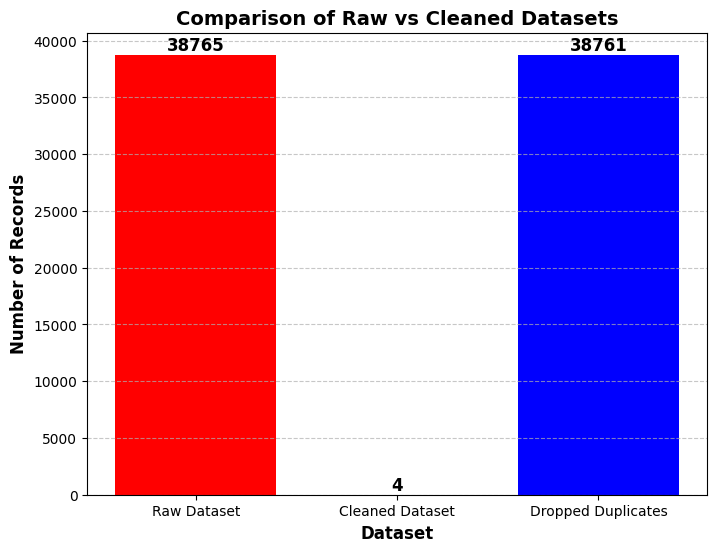

Raw Records: 38765, Cleaned Records: 4, Dropped Duplicates: 38761
Deduplication Effectiveness: 99.99% of records removed.
Retention Rate: 0.01% of records kept.


In [12]:
import pandas as pd
import matplotlib.pyplot as plt

def process_deduplication(raw_file, subset_columns):
    """
    Processes the dataset by:
    1. Identifying and extracting duplicate records based on non-empty subset columns.
    2. Generating a cleaned dataset without duplicates.
    3. Visualizing the effectiveness of deduplication.
    """
    
     # Load the raw dataset
    df = pd.read_csv(raw_file, low_memory=False, dtype=str)  # Read all columns as strings to avoid dtype issues
    # df[['mobile']] = df[['mobile']].fillna('').replace('nan', '') 
    # df[['phone', 'zip']] = df[['phone', 'zip']].fillna('').replace('nan', '') 
    # Filter subset columns that exist in the dataset
    subset_filtered = [col for col in subset_columns if col in df.columns]

    # Mark all duplicates (excluding the first occurrence)
    mask_duplicates = df.duplicated(subset=subset_filtered, keep='first')

    # Extract duplicate records (excluding the first preserved one)
    duplicates_df = df[mask_duplicates]

    # Cleaned data: keep the first occurrence of each duplicate group
    cleaned_df = df[~mask_duplicates]
    
    # Save outputs
    clean_file = raw_file.replace(".csv", "_cleaned.csv")
    duplicates_file = raw_file.replace(".csv", "_duplicates.csv")
    cleaned_df.to_csv(clean_file, index=False)
    duplicates_df.to_csv(duplicates_file, index=False)
    
    # Compute statistics
    records_raw = len(df)
    records_clean = len(cleaned_df)
    records_duplicates = len(duplicates_df)
    
    # Visualization
    labels = ['Raw Dataset', 'Cleaned Dataset', 'Dropped Duplicates']
    values = [records_raw, records_clean, records_duplicates]
    colors = ['red', 'green', 'blue']
    
    plt.figure(figsize=(8, 6))
    bars = plt.bar(labels, values, color=colors)
    plt.xlabel("Dataset", fontsize=12, fontweight='bold')
    plt.ylabel("Number of Records", fontsize=12, fontweight='bold')
    plt.title("Comparison of Raw vs Cleaned Datasets", fontsize=14, fontweight='bold')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.ticklabel_format(useOffset=False, style='plain', axis='y')  # Ensure normal values on y-axis
    
    
    for bar in bars:
        yval = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, yval + 0.05, int(yval), ha='center', va='bottom', fontsize=12, fontweight='bold')
    
    plt.show()
    
    print(f"Raw Records: {records_raw}, Cleaned Records: {records_clean}, Dropped Duplicates: {records_duplicates}")
    print(f"Deduplication Effectiveness: {(records_duplicates / records_raw) * 100:.2f}% of records removed.")
    print(f"Retention Rate: {(records_clean / records_raw) * 100:.2f}% of records kept.")
    
    return clean_file, duplicates_file

# Example Usage 146491 
raw_file = f"{TO_BE_INGESTED_PATH}final/v2/" + "processed_processed_messy_sample_4.csv"  # Adjust the path as needed
# subset_columns = ['email', 'mobile']  # Adjust based on which columns are relevant for deduplication
subset_columns = ['email']  # Adjust based on which columns are relevant for deduplication
cleaned_output, duplicates_output = process_deduplication(raw_file, subset_columns)


### Chunked Deduplication

In [ ]:
import pandas as pd
import os
import hashlib

def make_key(row, subset_columns):
    values = []
    for col in subset_columns:
        value = row.get(col, "")
        value = "" if pd.isna(value) else str(value).strip().lower()
        values.append(value)

    raw_key = "|".join(values)
    return hashlib.md5(raw_key.encode("utf-8")).hexdigest()


def process_deduplication_large_file(raw_file, subset_columns, chunksize=100_000):
    clean_file = raw_file.replace(".csv", "_cleaned.csv")
    duplicates_file = raw_file.replace(".csv", "_duplicates.csv")

    seen_keys = set()

    raw_count = 0
    clean_count = 0
    duplicate_count = 0

    first_clean_write = True
    first_duplicate_write = True

    for chunk in pd.read_csv(
        raw_file,
        chunksize=chunksize,
        dtype=str,
        encoding="utf-8-sig",
        on_bad_lines="skip"
    ):
        subset_filtered = [col for col in subset_columns if col in chunk.columns]

        if not subset_filtered:
            raise ValueError(f"None of these columns exist in file: {subset_columns}")

        clean_rows = []
        duplicate_rows = []

        for _, row in chunk.iterrows():
            raw_count += 1

            key = make_key(row, subset_filtered)

            if key in seen_keys:
                duplicate_rows.append(row)
                duplicate_count += 1
            else:
                seen_keys.add(key)
                clean_rows.append(row)
                clean_count += 1

        if clean_rows:
            pd.DataFrame(clean_rows).to_csv(
                clean_file,
                mode="a",
                index=False,
                header=first_clean_write
            )
            first_clean_write = False

        if duplicate_rows:
            pd.DataFrame(duplicate_rows).to_csv(
                duplicates_file,
                mode="a",
                index=False,
                header=first_duplicate_write
            )
            first_duplicate_write = False

    print(f"Raw Records: {raw_count}")
    print(f"Cleaned Records: {clean_count}")
    print(f"Dropped Duplicates: {duplicate_count}")

    if raw_count > 0:
        print(f"Deduplication Effectiveness: {(duplicate_count / raw_count) * 100:.2f}% removed.")
        print(f"Retention Rate: {(clean_count / raw_count) * 100:.2f}% kept.")

    return clean_file, duplicates_file


raw_file = "{TO_BE_INGESTED_PATH}final/samples_merged.csv"
subset_columns = ["email"]

cleaned_output, duplicates_output = process_deduplication_large_file(
    raw_file,
    subset_columns,
    chunksize=100_000
)

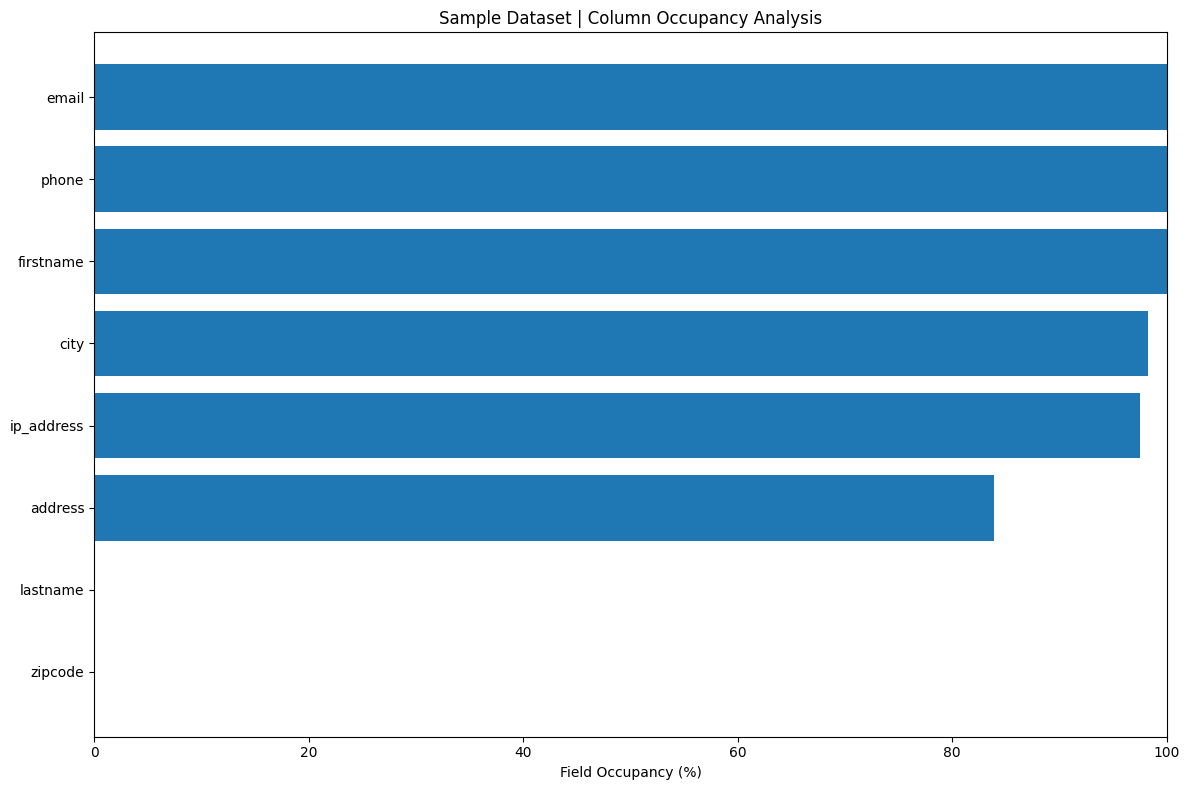

,Occupancy %
zipcode,0.002580
lastname,0.005159
address,83.846253
ip_address,97.531278
city,98.243261
firstname,99.992261
phone,99.997420
email,99.997420


In [ ]:

def column_occupancy_report(file_path):
    df = pd.read_csv(file_path)

    total_rows = len(df)

    occupancy = {}

    for col in df.columns:
        non_null = df[col].replace(["", "None", "null"], pd.NA).notna().sum()
        occupancy[col] = (non_null / total_rows) * 100

    occupancy_df = pd.DataFrame.from_dict(
        occupancy, orient='index', columns=['Occupancy %']
    ).sort_values(by='Occupancy %')

    # Plot
    plt.figure(figsize=(12, 8))
    plt.barh(occupancy_df.index, occupancy_df['Occupancy %'])
    plt.xlabel("Field Occupancy (%)")
    plt.title("Sample Dataset | Column Occupancy Analysis")
    plt.xlim(0, 100)
    plt.tight_layout()
    plt.show()

    return occupancy_df


# Example Usage
raw_file = f"{TO_BE_INGESTED_PATH}final/v2/" + "processed_processed_messy_sample_4.csv"
column_occupancy_report(raw_file)


In [14]:
def validate_dob(name_series):
    name_errors = []
    #    name_pattern = re.compile(r'^[a-zA-Z&|#(). ]+$')
    # Pattern to check if the name contains only letters
    name_pattern = re.compile(r'^[0-9&|#()-/. ]+$')

    for i, name in enumerate(name_series):
        if not re.match(name_pattern, str(name)):
            name_errors.append(f"Invalid characters in name in row {i + 1}: {name}")

    return name_errors

In [15]:
def validate_usernames(name_series):
    name_errors = []
    #    name_pattern = re.compile(r'^[a-zA-Z&|#(). ]+$')
    # Pattern to check if the name contains only letters
    name_pattern = re.compile(r'^[a-zA-Z0-9&|#(). ]+$')

    for i, name in enumerate(name_series):
        if not re.match(name_pattern, str(name)):
            name_errors.append(f"Invalid characters in name in row {i + 1}: {name}")

    return name_errors

In [16]:
def validate_names(name_series):
    name_errors = []
    #    name_pattern = re.compile(r'^[a-zA-Z&|#(). ]+$')
    # Pattern to check if the name contains only letters
    name_pattern = re.compile(r'^[a-zA-Z]+$')

    for i, name in enumerate(name_series):
        if not re.match(name_pattern, str(name)):
            name_errors.append(f"Invalid characters in name in row {i + 1}: {name}")

    return name_errors

In [17]:
def validate_emails(email_series):
    email_errors = []

   # Improved email pattern
    email_pattern = re.compile(r'^[a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}$')

    for i, email in enumerate(email_series):
       # Check if the email is blank
        if pd.isnull(email) or str(email).strip() == '':
            continue  # Skip validation for blank emails

        # Check if the email matches the pattern
        if not re.match(email_pattern, str(email)):
            email_errors.append(f"Invalid email address in row {i + 1}: {email}")

    return email_errors

In [18]:
def generate_report(validation_errors, total_rows):
    if validation_errors:
        # Plot a bar chart of the number of errors per column
        columns = list(validation_errors.keys())
        error_count = [len(error) for error in validation_errors.values()]

        # Calculate the percentage of errors
        error_percentage = [(count / total_rows) * 100 for count in error_count]
         # Manually set the size of the figure
        plt.figure(figsize=(10, 6))

        plt.bar(columns, error_count)
        plt.xlabel('Columns')
        plt.ylabel('Error Count')
        plt.title('Sample Dataset - Record Validation Testing')
        
        # Add error count labels on the bars
        # for i, count in enumerate(error_count): 
         # Add error percentage labels on the bars
        for i, percentage in enumerate(error_percentage):
            # plt.text(i, count + 0.1, str(count), ha='center', va='bottom')
            plt.text(i, percentage + 0.1, f"{percentage:.2f}%", ha='center', va='bottom')

        # Automatically adjust layout to prevent overlapping
       # plt.tight_layout()

        plt.show()
    else:
        print("Data type validation successful!")


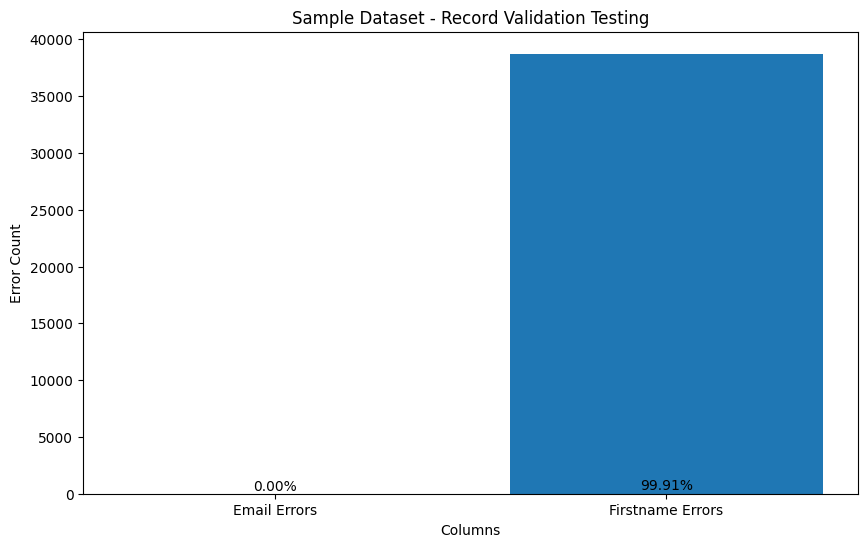

Verification Testing Complete. 

 Total 38765 Rows Tested, 38732 Invalid Records FOUND!
Email Errors []

Firstname Errors ['Invalid characters in name in row 38754: Ксения', 'Invalid characters in name in row 38755: Елена', 'Invalid characters in name in row 38756: Юлия', 'Invalid characters in name in row 38757: Иван', 'Invalid characters in name in row 38758: Ирина', 'Invalid characters in name in row 38759: Виталий', 'Invalid characters in name in row 38760: Максим', 'Invalid characters in name in row 38761: Крис', 'Invalid characters in name in row 38762: Татьяна', 'Invalid characters in name in row 38763: Оксана', 'Invalid characters in name in row 38764: Екатерина', 'Invalid characters in name in row 38765: Александр']



In [19]:
file_path = f"{TO_BE_INGESTED_PATH}final/v2/" + "processed_processed_messy_sample_4.csv"
df = pd.read_csv(file_path, low_memory=False)
pd.options.display.min_rows = 10

# dob_errors = validate_dob(df["dob"])
email_errors = validate_emails(df["email"])
firstname_errors = validate_names(df["firstname"])

# Combine all errors into one dictionary
all_errors = {
    'Email Errors': email_errors,
    'Firstname Errors': firstname_errors
    # 'DOB Errors': dob_errors
}

# Using the shape attribute
num_rows, num_columns = df.shape
# total_errors = len(email_errors) + len(state_errors) + len(zip_errors) + len(country_errors) + len(city_errors)
# total_errors = len(email_errors) + len(firstname_errors) + len(dob_errors)
total_errors = len(email_errors) + len(firstname_errors)
# total_errors = len(firstname_errors)
generate_report(all_errors, num_rows)

print(f'Verification Testing Complete. \n\n Total {num_rows} Rows Tested, {total_errors} Invalid Records FOUND!')
print(f'Email Errors {email_errors[-10:]}')
print()
# print(f'DOB Errors {dob_errors[-10:]}')
# print()
print(f'Firstname Errors {firstname_errors[-12:]}')
print()